# ML - Tugas 1

Jalankan seluruh sel secara berurutan. Dataset tersedia di folder `datasets` pada root repositori.

In [1]:
# -*- coding: utf-8 -*-
"""ML_Tgs1.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/12uSHM2fsd0UqbrRZsdsxdip5HvMfxin2
"""

# ============================================================
# LEARNING CURVE — TELCO CUSTOMER CHURN
# Copas seluruh kode ke SATU cell Google Colab, lalu Run.
# ============================================================

import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

try:
    from IPython.display import display
except ImportError:
    display = print

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    learning_curve,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
)

In [2]:
from pathlib import Path

# Mendukung script Python dan notebook yang dijalankan dari folder proyek/pertemuan.
BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
PROJECT_DIR = next(
    (p for p in (BASE_DIR, BASE_DIR.parent) if (p / "datasets").is_dir()),
    BASE_DIR.parent,
)

# ============================================================
# 1. MEMBACA DATASET
# Jika file sudah ada, tidak perlu upload ulang.
# ============================================================

FILENAME = PROJECT_DIR / "datasets" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

if Path(FILENAME).exists():
    df = pd.read_csv(FILENAME)
else:
    from google.colab import files

    print("Pilih file CSV Telco Customer Churn.")
    uploaded = files.upload()

    csv_names = [
        name for name in uploaded
        if name.lower().endswith(".csv")
    ]

    if len(csv_names) != 1:
        raise ValueError("Upload tepat satu file CSV.")

    df = pd.read_csv(io.BytesIO(uploaded[csv_names[0]]))

In [3]:
# ============================================================
# 2. MEMBERSIHKAN FORMAT DATA
# Belum menghitung median atau mempelajari pola dari data.
# ============================================================

df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip().replace("", np.nan)

# TotalCharges memiliki nilai kosong berbentuk spasi.
# Konversi ke angka; nilai yang tidak valid menjadi NaN.
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce",
)

if not df["Churn"].isin(["Yes", "No"]).all():
    raise ValueError(
        "Target Churn harus Yes/No dan tidak boleh kosong."
    )

if (
    df["customerID"].isna().any()
    or df["customerID"].duplicated().any()
):
    raise ValueError(
        "customerID kosong/duplikat: periksa sebelum membagi data."
    )

print("Versi scikit-learn:", sklearn.__version__)
print("Ukuran dataset:", df.shape)
print(
    "TotalCharges kosong:",
    df["TotalCharges"].isna().sum(),
)

display(
    df["Churn"]
    .value_counts()
    .rename_axis("Churn")
    .to_frame("Jumlah")
)

Versi scikit-learn: 1.9.1
Ukuran dataset: (7043, 21)
TotalCharges kosong: 11


C:\Users\ADAMYA~1\AppData\Local\Temp\ipykernel_82440\615622030.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


,Jumlah
Churn,
No,5174
Yes,1869


In [4]:
# ============================================================
# 3. MENENTUKAN FITUR X DAN TARGET y
# customerID bukan fitur untuk memprediksi churn.
# ============================================================

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# 80% untuk pengembangan, 20% untuk ujian akhir.
# stratify menjaga proporsi kelas saat pembagian.
# random_state membuat pembagian dapat direproduksi.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

print(
    f"Data pengembangan: {len(X_train)}"
    f" | Test terpisah: {len(X_test)}"
)

Data pengembangan: 5634 | Test terpisah: 1409


In [5]:
# ============================================================
# 4. PREPROCESSING DI DALAM PIPELINE
# Median dan encoding dipelajari hanya dari bagian training
# pada setiap fold, untuk menghindari kebocoran data.
# ============================================================

numeric_cols = X.select_dtypes(
    include="number"
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude="number"
).columns.tolist()

preprocess = ColumnTransformer([
    (
        "numeric",
        SimpleImputer(strategy="median"),
        numeric_cols,
    ),
    (
        "category",
        Pipeline([
            (
                "imputer",
                SimpleImputer(strategy="most_frequent"),
            ),
            (
                "encoder",
                OneHotEncoder(handle_unknown="ignore"),
            ),
        ]),
        categorical_cols,
    ),
])

In [6]:
# ============================================================
# 5. MEMBUAT MODEL RANDOM FOREST
# Model awal/baseline, belum melalui tuning.
# ============================================================

model = Pipeline([
    ("preprocess", preprocess),
    (
        "rf",
        RandomForestClassifier(
            n_estimators=150,
            max_depth=None,
            min_samples_leaf=1,
            class_weight="balanced",
            random_state=42,
            n_jobs=1,
        ),
    ),
])

# n_estimators=150  : memakai 150 pohon keputusan.
# max_depth=None   : kedalaman pohon tidak dibatasi.
# min_samples_leaf : minimal 1 sampel pada daun.
# class_weight     : menyesuaikan bobot dengan frekuensi kelas.
# n_jobs=1         : paralelisasi diatur pada learning_curve.

In [7]:
# ============================================================
# 6. MENGHITUNG LEARNING CURVE
# 8 ukuran data x 5 fold = 40 pelatihan.
# Test terpisah TIDAK digunakan di sini.
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

print(
    "Menghitung learning curve:"
    " 8 ukuran x 5 fold = 40 training..."
)

sizes, train_scores, val_scores = learning_curve(
    estimator=model,
    X=X_train,
    y=y_train,
    cv=cv,
    train_sizes=np.linspace(0.1, 1.0, 8),
    scoring="f1",  # F1 untuk kelas positif 1 = Yes/churn.
    shuffle=True,
    random_state=42,
    n_jobs=2,
    error_score="raise",
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

results = pd.DataFrame({
    "Jumlah_training_per_fold": sizes,
    "F1_train_mean": train_mean,
    "F1_train_std": train_std,
    "F1_validation_mean": val_mean,
    "F1_validation_std": val_std,
    "Gap_train_validation": train_mean - val_mean,
})

display(results.round(4))

Menghitung learning curve: 8 ukuran x 5 fold = 40 training...


,Jumlah_training_per_fold,F1_train_mean,F1_train_std,F1_validation_mean,F1_validation_std,Gap_train_validation
0,450,0.9921,0.0049,0.5994,0.0177,0.3927
1,1030,0.9930,0.0046,0.6017,0.0094,0.3913
2,1609,0.9924,0.0037,0.5941,0.0127,0.3983
3,2189,0.9913,0.0023,0.5964,0.0124,0.3948
4,2768,0.9912,0.0021,0.6000,0.0271,0.3912
5,3348,0.9913,0.0010,0.6017,0.0148,0.3896
6,3927,0.9912,0.0009,0.5921,0.0197,0.3992
7,4507,0.9907,0.0019,0.5994,0.0187,0.3913


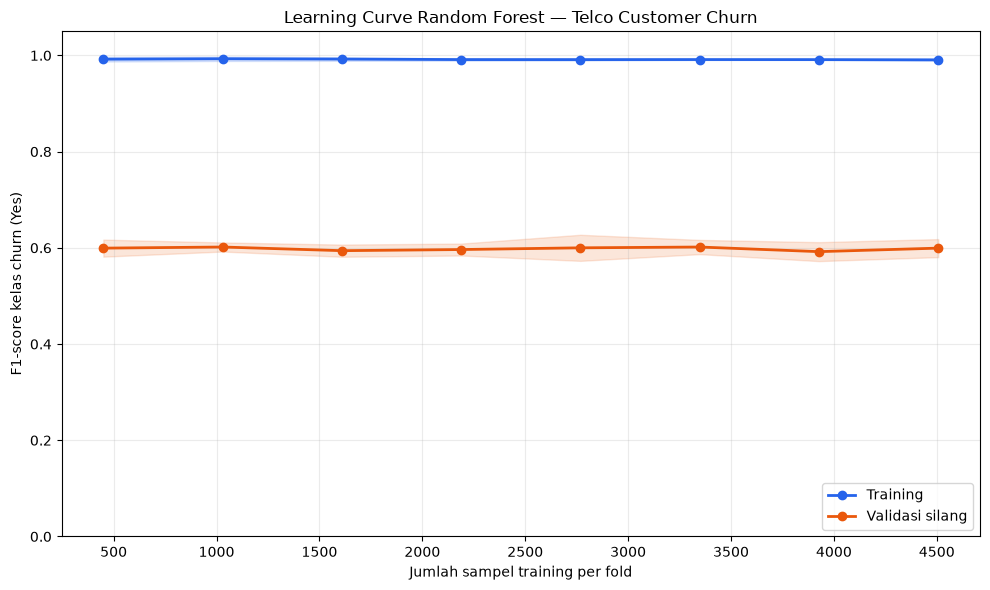

Titik terakhir: train=0.9907, validasi=0.5994, gap=0.3913
Area bayangan = +/- 1 standar deviasi antar fold, bukan confidence interval.


In [8]:
# ============================================================
# 7. MENAMPILKAN GRAFIK LEARNING CURVE
# Bayangan = +/- 1 standar deviasi, bukan confidence interval.
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

for mean, std, color, label in [
    (train_mean, train_std, "#2563eb", "Training"),
    (val_mean, val_std, "#ea580c", "Validasi silang"),
]:
    ax.plot(
        sizes,
        mean,
        "o-",
        color=color,
        label=label,
        linewidth=2,
    )

    ax.fill_between(
        sizes,
        np.clip(mean - std, 0, 1),
        np.clip(mean + std, 0, 1),
        color=color,
        alpha=0.15,
    )

ax.set(
    title="Learning Curve Random Forest — Telco Customer Churn",
    xlabel="Jumlah sampel training per fold",
    ylabel="F1-score kelas churn (Yes)",
    ylim=(0, 1.05),
)

ax.grid(alpha=0.25)
ax.legend(loc="lower right")

fig.tight_layout()
fig.savefig("learning_curve_telco.png", dpi=180)
plt.show()

results.to_csv(
    "learning_curve_scores.csv",
    index=False,
)

print(
    f"Titik terakhir: train={train_mean[-1]:.4f}, "
    f"validasi={val_mean[-1]:.4f}, "
    f"gap={train_mean[-1] - val_mean[-1]:.4f}"
)

print(
    "Area bayangan = +/- 1 standar deviasi antar fold,"
    " bukan confidence interval."
)

Melatih model akhir dan mengevaluasi test terpisah...


Accuracy test : 0.7665
F1 churn test : 0.5882
ROC-AUC test  : 0.8226
               precision    recall  f1-score   support

No (bertahan)     0.8587    0.8164    0.8370      1035
  Yes (churn)     0.5529    0.6283    0.5882       374

     accuracy                         0.7665      1409
    macro avg     0.7058    0.7224    0.7126      1409
 weighted avg     0.7776    0.7665    0.7710      1409



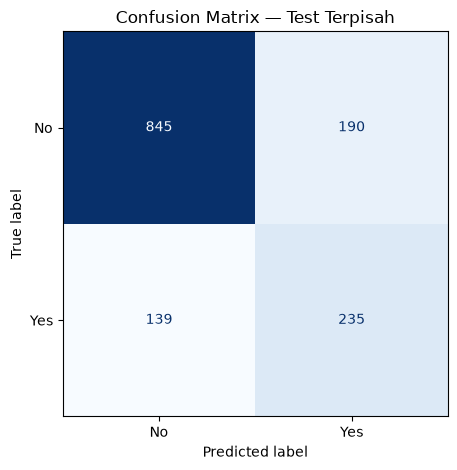

File tersimpan: learning_curve_telco.png, learning_curve_scores.csv
Unduh melalui panel Files di sisi kiri Colab.


In [9]:
# ============================================================
# 8. TRAINING AKHIR DAN EVALUASI TEST
# Latih pada semua data pengembangan.
# Gunakan test untuk evaluasi akhir, bukan memilih parameter.
# ============================================================

print("Melatih model akhir dan mengevaluasi test terpisah...")

model.fit(X_train, y_train)

pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]

print(
    f"Accuracy test : {accuracy_score(y_test, pred):.4f}"
)
print(
    f"F1 churn test : {f1_score(y_test, pred):.4f}"
)
print(
    f"ROC-AUC test  : {roc_auc_score(y_test, prob):.4f}"
)

print(
    classification_report(
        y_test,
        pred,
        labels=[0, 1],
        target_names=["No (bertahan)", "Yes (churn)"],
        digits=4,
        zero_division=0,
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred,
    labels=[0, 1],
    display_labels=["No", "Yes"],
    cmap="Blues",
    colorbar=False,
)

plt.title("Confusion Matrix — Test Terpisah")
plt.tight_layout()
plt.show()

print(
    "File tersimpan:"
    " learning_curve_telco.png, learning_curve_scores.csv"
)
print("Unduh melalui panel Files di sisi kiri Colab.")